# Frequent Category (Mode) Imputation

Frequent category imputation (also known as **mode imputation**) consists of replacing missing values in categorical variables with the most frequent category (the statistical mode).

---

## Learning Objectives
By the end of this notebook, you will be able to:
1. Understand the assumptions and appropriate use cases for mode imputation.
2. Recognize the critical risk of **over-representing the dominant category** when missingness is high.
3. Prevent data leakage by computing the mode strictly on the training set.
4. Implement mode imputation using both **pandas** and **scikit-learn's `SimpleImputer`**.
5. Compare category distributions before and after imputation to evaluate distortion.

---
## 1. When to Use (and When to AVOID) Mode Imputation

| Feature | Recommended | Caution |
| :--- | :--- | :--- |
| **Missing Percentage** | **Low (< 5%)**: Replacing a few missing rows with the mode has minimal impact on category proportions. | **High (> 10-20%)**: Artificially inflates the majority category, distorting natural relationships and variance. |
| **Missing Mechanism** | Missing Completely at Random (MCAR). | Missing Not at Random (MNAR) — e.g., missing fireplace rating usually means "No Fireplace". For such features, **Missing Category Imputation** (Notebook 04) is far superior. |

> **Key Rule**: If missingness is high, adding a `"Missing"` category (Notebook 04) is safer than forcing all missing rows into the mode.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Matplotlib styling
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['font.size'] = 10

---
## 2. Loading Data & Splitting Train/Test Sets

We examine two categorical features from the Ames House Prices dataset with very different levels of missingness:
- **`BsmtQual`**: Evaluates basement height (low missingness: ~2.5%).
- **`FireplaceQu`**: Evaluates fireplace quality (high missingness: ~47%).

In [2]:
cols_to_use = [
    "BsmtQual",     # Basement quality
    "FireplaceQu",  # Fireplace quality
    "SalePrice",    # Target
]

data_path = '../datasets/houseprice.csv'
if not os.path.exists(data_path):
    data_path = 'https://raw.githubusercontent.com/cmps460s26/cmps460-content/refs/heads/main/examples/03.dp/datasets/houseprice.csv'

data = pd.read_csv(data_path, usecols=cols_to_use)

# Split into predictors and target
X = data.drop("SalePrice", axis=1)
y = data["SalePrice"]

# Train / Test split BEFORE analyzing categories
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

X_train shape: (1022, 2)
X_test shape:  (438, 2)


---
## 3. Analyzing Missingness & Category Frequencies

Let's inspect the percentage of missing values in `X_train`.

In [3]:
# Check missing percentage on training set
missing_rates = X_train.isnull().mean()
for col in X_train.columns:
    print(f"- {col:15s}: {missing_rates[col]*100:.2f}% missing ({X_train[col].isnull().sum()} rows)")

- BsmtQual       : 2.35% missing (24 rows)
- FireplaceQu    : 46.77% missing (478 rows)


In [4]:
# Check the mode (most frequent category) for each variable
for col in X_train.columns:
    mode_val = X_train[col].mode().iloc[0]
    freq = (X_train[col] == mode_val).mean() * 100
    print(f"- {col:15s}: Mode = '{mode_val}' (constitutes {freq:.1f}% of observed rows)")

- BsmtQual       : Mode = 'TA' (constitutes 45.3% of observed rows)
- FireplaceQu    : Mode = 'Gd' (constitutes 25.0% of observed rows)


---
## 4. Method 1: Imputation Using Pandas

We compute the mode strictly on `X_train`, convert to a dictionary, and fill missing entries on both `X_train` and `X_test`.

In [5]:
# Extract mode for each column from X_train
imputation_dict = X_train.mode().iloc[0].to_dict()
print("Computed Mode Imputation Dictionary from X_train:")
print(imputation_dict)

Computed Mode Imputation Dictionary from X_train:
{'BsmtQual': 'TA', 'FireplaceQu': 'Gd'}


In [6]:
# Create copies for pandas implementation
X_train_pd = X_train.copy()
X_test_pd = X_test.copy()

# Apply imputation
X_train_pd.fillna(imputation_dict, inplace=True)
X_test_pd.fillna(imputation_dict, inplace=True)

# Corroborate that missing values are resolved
print(f"Nulls in X_train after imputation: {X_train_pd.isnull().sum().to_dict()}")
print(f"Nulls in X_test after imputation:  {X_test_pd.isnull().sum().to_dict()}")

Nulls in X_train after imputation: {'BsmtQual': 0, 'FireplaceQu': 0}
Nulls in X_test after imputation:  {'BsmtQual': 0, 'FireplaceQu': 0}


---
## 5. Method 2: Imputation Using Scikit-Learn `SimpleImputer`

With scikit-learn, we set `strategy='most_frequent'`. This transformer learns the mode during `.fit()` on `X_train` and applies it during `.transform()`.

In [7]:
# Initialize SimpleImputer with most_frequent strategy
imputer = SimpleImputer(strategy='most_frequent')
imputer.set_output(transform="pandas")

# Fit on training set only
imputer.fit(X_train)

# Inspect the learned mode statistics
print("SimpleImputer learned mode per feature:")
for col, stat in zip(X_train.columns, imputer.statistics_):
    print(f"  {col:15s}: {stat}")

SimpleImputer learned mode per feature:
  BsmtQual       : TA
  FireplaceQu    : Gd


In [8]:
# Transform both train and test sets
X_train_sk = imputer.transform(X_train)
X_test_sk = imputer.transform(X_test)

# Verify clean output
print(f"Remaining nulls in train: {X_train_sk.isnull().sum().sum()}")
print(f"Remaining nulls in test:  {X_test_sk.isnull().sum().sum()}")
X_train_sk.head()

Remaining nulls in train: 0
Remaining nulls in test:  0


,BsmtQual,FireplaceQu
64,Gd,Gd
682,Gd,Gd
960,TA,Gd
1384,TA,Gd
1100,TA,Gd


---
## 6. Evaluating Distribution Impact: Low vs. High Missingness

Let's visualize the critical difference when applying mode imputation to a low-missingness feature (`BsmtQual`: ~2.5%) vs a high-missingness feature (`FireplaceQu`: ~47%).

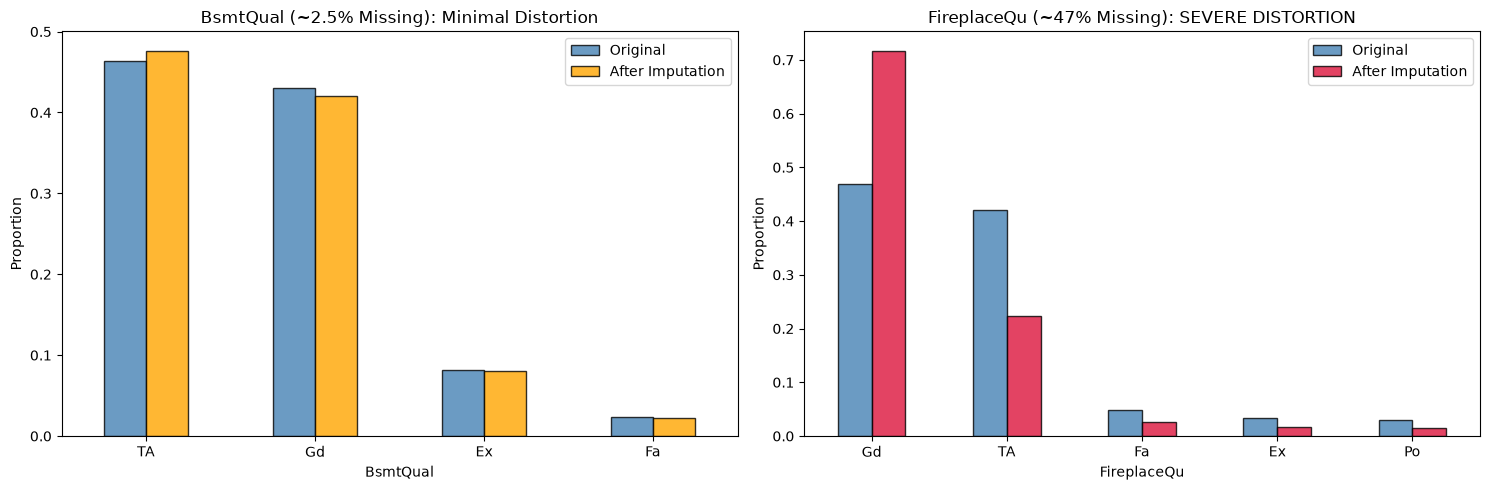

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot BsmtQual (Low missingness ~ 2.5%)
df_bsmt = pd.DataFrame({
    'Original': X_train['BsmtQual'].value_counts(normalize=True),
    'After Imputation': X_train_sk['BsmtQual'].value_counts(normalize=True)
})
df_bsmt.plot(kind='bar', ax=ax1, color=['steelblue', 'orange'], alpha=0.8, edgecolor='black')
ax1.set_title('BsmtQual (~2.5% Missing): Minimal Distortion')
ax1.set_ylabel('Proportion')
ax1.tick_params(axis='x', rotation=0)

# Plot FireplaceQu (High missingness ~ 47%)
df_fire = pd.DataFrame({
    'Original': X_train['FireplaceQu'].value_counts(normalize=True),
    'After Imputation': X_train_sk['FireplaceQu'].value_counts(normalize=True)
})
df_fire.plot(kind='bar', ax=ax2, color=['steelblue', 'crimson'], alpha=0.8, edgecolor='black')
ax2.set_title('FireplaceQu (~47% Missing): SEVERE DISTORTION')
ax2.set_ylabel('Proportion')
ax2.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Pedagogical Analysis:
1. **`BsmtQual` (Left Plot)**: Because missingness was only ~2.5%, the proportions before and after imputation are virtually identical. Mode imputation is safe here.
2. **`FireplaceQu` (Right Plot)**: Over 47% of the data was missing! Forcing all missing records into the mode (`Gd`) causes `Gd` to artificially jump from ~50% to over 75% of the entire dataset. In reality, houses with missing fireplace ratings simply have **no fireplace**. Imputing "Gd" misleads the model into believing those houses have good fireplaces!

---
## 7. Summary & Best Practices Checklist

| Metric | Rule of Thumb |
| :--- | :--- |
| **Safe to Use Mode** | Categorical features with **< 5%** missing data and assumed MCAR. |
| **Unsafe to Use Mode** | Categorical features with **> 10%** missing data, or where missingness represents an absence/separate state. |
| **Better Alternative for High Missingness** | **Missing Category Imputation** (creating a `"Missing"` or `"None"` label, demonstrated in Notebook 04). |
| **Data Leakage** | Always fit `mode()` or `SimpleImputer(strategy='most_frequent')` on `X_train` only. |
